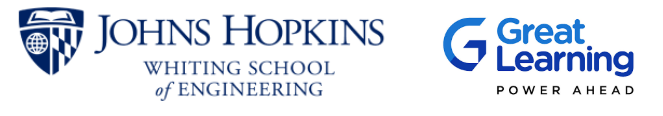

<font size=10>**End-Term / Final Project**</font>

<font size=6>**AI for Research Proposal Automation**</font>


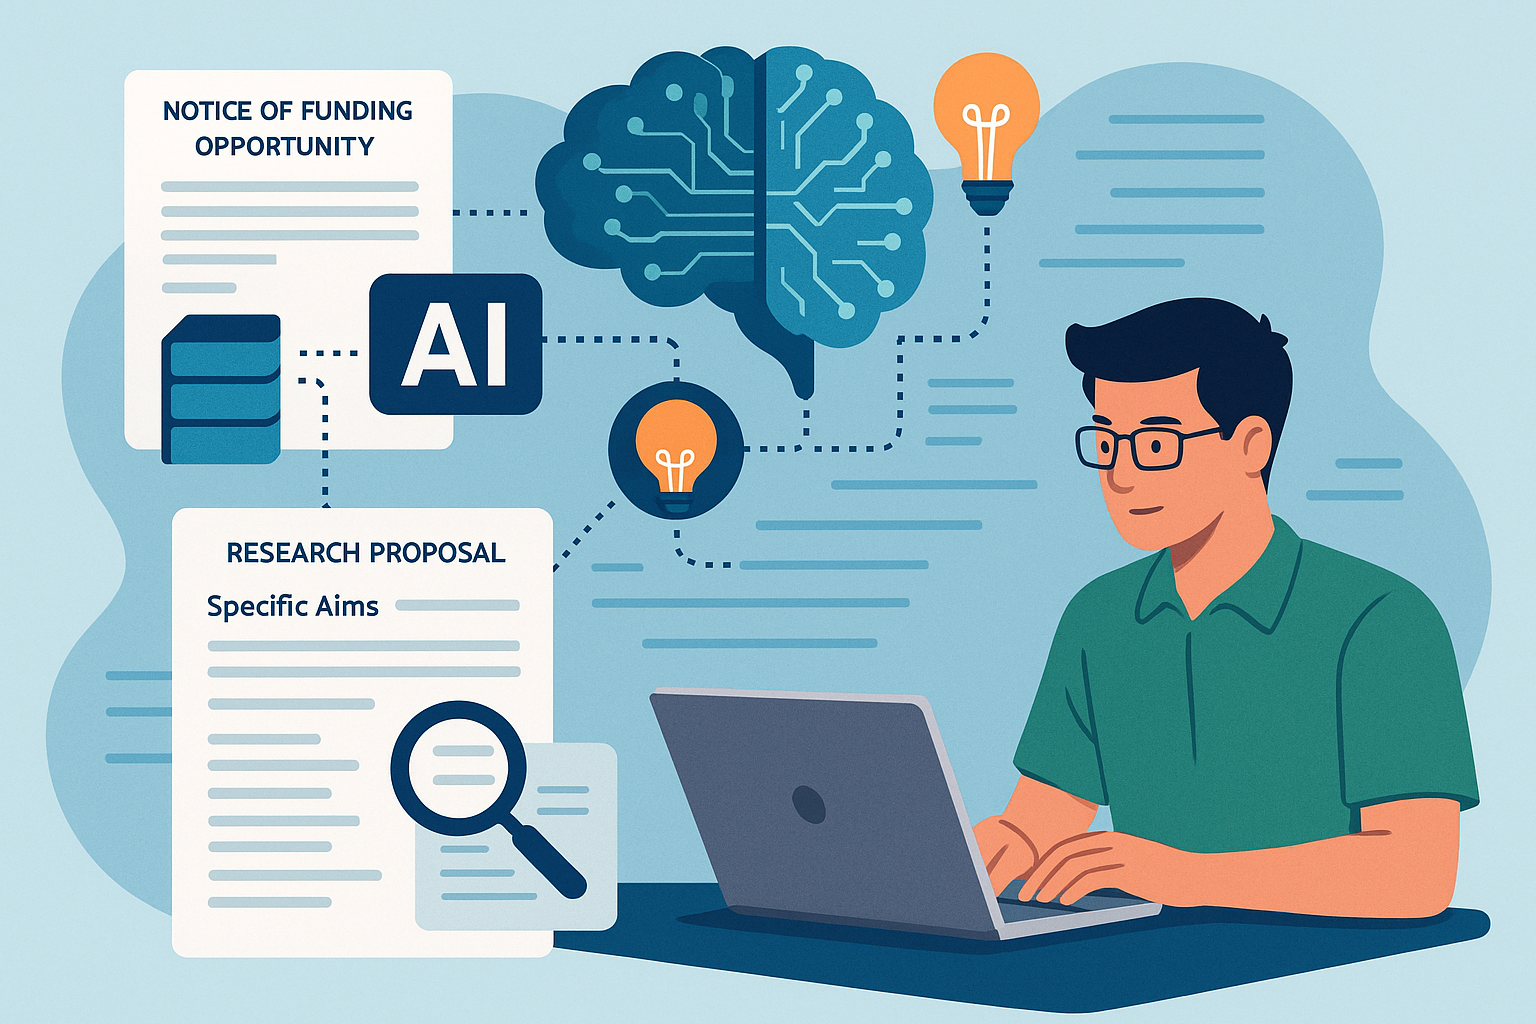

### **Business Problem - Create an AI system which will help you writing the research proposal aligning with the NOFO Document**
   



Meet Dr. Ian McCulloh, a seasoned research advisor and a leading voice in interdisciplinary science. Over the years, his lab has explored everything from AI for counterterrorism to social network analysis in neuroscience. His publication portfolio is vast, rich, and... chaotic.

When the National Institute of Mental Health released a new NOFO (Notice of Funding Opportunity) seeking innovative digital health solutions for mental health equity, Dr. Ian saw an opportunity. But there was a problem: despite his extensive work, none of his existing research was directly aligned with digital mental health interventions. And with NIH deadlines looming, manually identifying relevant angles and generating a competitive proposal would be a massive lift.

Dr. Ian wished for a smart assistant—one that could digest his past work, interpret the NOFO’s intent, spark new research directions, and even help draft proposal sections.

**The Challenge:**

Organizations and researchers often maintain large archives of publications and prior work. When responding to competitive grants—especially highly specific ones like NIH NOFOs—it becomes extremely difficult and time-consuming to:

1. Align past work with a new funding call.
2. Extract relevant expertise from unrelated projects.
3. Ideate novel, fundable research proposals tailored to complex criteria.
4. Generate high-quality text for grant submission that satisfies technical and scientific review criteria.

The manual effort to sift through dense research documents, match them to nuanced funding criteria, and write compelling, compliant proposals is labor-intensive, inconsistent, and prone to missed opportunities.

### **The Case Study Approach**

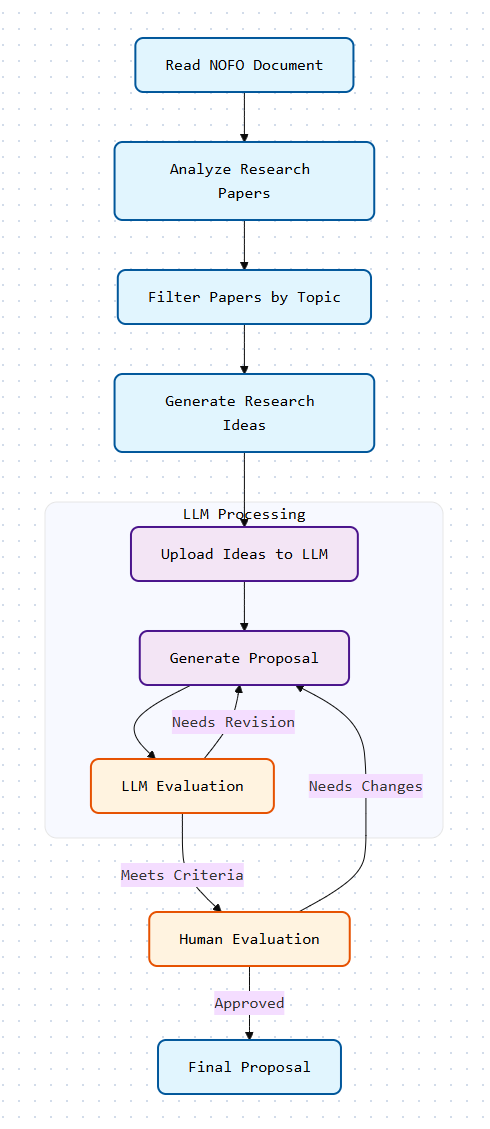

**Objective**
1. Develop a generative AI-powered system using LLMs to automate and optimize the creation of NIH research proposals.
2. The tool will identify relevant prior research, generate aligned project ideas, and draft high-quality proposal content tailored to specific NOFO requirements.

## **Setup - [3 Marks]**
---
<font color=Red>**Note:**</font> *2 marks for Loading the Config file details and 1 mark for the LLM Configuration.*

# After you have installed the necessary libraries in the next cell, you should click on Cancel when prompted to restart

In [1]:
# Library Installations

!pip install numpy==1.26.4 \
  langchain-openai==0.3.27 \
  langchain-core==0.3.68 \
  langchain==0.3.26 \
  langchain-community==0.3.20 \
  pypdf==5.4.0 \
  faiss-cpu==1.8.0 \
  markdown-pdf==1.7 \
  --force-reinstall --no-cache-dir

!pip uninstall langgraph-prebuilt -y
# You may see an error message which can be ignored

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 7.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.4/109.4 kB 23.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.2/94.2 kB 274.6 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of langchain-text-splitters to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.0/42.0 kB 274.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 313.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 278.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 244.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 65.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.4/70.4 kB 305.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.4/441.4 kB 248.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

Found existing installation: langgraph-prebuilt 1.1.0
Uninstalling langgraph-prebuilt-1.1.0:
  Successfully uninstalled langgraph-prebuilt-1.1.0


In [2]:
# Unzip the Project files zip file
!unzip "/content/Project_Files.zip"

Archive:  /content/Project_Files.zip
   creating: Project Files/
   creating: Project Files/For Reference - Generated Sample Reseach Proposals/
  inflating: Project Files/For Reference - Generated Sample Reseach Proposals/P1 - Enhancing Mental Health Engagement through Adaptive Social Media Interventions.pdf  
  inflating: Project Files/For Reference - Generated Sample Reseach Proposals/P2 - Neurofeedback-Driven Digital Interventions for Substance Use Disorders.pdf  
  inflating: Project Files/For Reference - Generated Sample Reseach Proposals/P3 - AI-Enhanced Misinformation Countermeasures in Mental Health.pdf  
  inflating: Project Files/For Reference - Generated Sample Reseach Proposals/P4 - Personalized Mental Health Interventions Using Neural Data.pdf  
  inflating: Project Files/For Reference - Generated Sample Reseach Proposals/P5 - Social Network Analysis for Suicide Prevention Messaging.pdf  
  inflating: Project Files/NOFO.pdf  
  inflating: Project Files/Research Proposal Te

In [3]:
# @title Loading the `config.json` file
import json
import os

# Load the JSON file and extract values
file_name = 'config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    os.environ['OPENAI_API_KEY'] = config.get("API_KEY") # Loading the API Key
    os.environ["OPENAI_BASE_URL"] = config.get("OPENAI_API_BASE") # Loading the API Base Url

In [4]:
# @title Defining the LLM Model - Use `gpt-4o-mini` Model
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

## **Step 1: Topic Extraction - [6 Marks]**

> **Read the NOFO doc and identify the topic for which the funding is to be given.**
---
<font color=Red>**Note:**</font> *4 marks are awarded for the prompt and 2 marks for the successful completion of this section, including debugging or modifying the code if necessary.*
   

In [5]:
from langchain.document_loaders import PyPDFLoader

# Reading the NOFO Document
pdf_file = "Project Files/NOFO.pdf"
pdf_loader = PyPDFLoader(pdf_file);
NOFO_pdf = pdf_loader.load()
#len(NOFO_pdf)

**TASK:** Write an LLM prompt that extracts the topic for which funding is being provided from the NOFO document, and instructs the model to respond with only the topic name.

In [6]:
topic_extraction_Prompt = f"""

You are an expert in analyzing Notices of Funding Opportunity (NOFOs).

Review the following NOFO document (.pdf) provided below and identify the primary research topic for which funding is being provided.

NOFO Document:
{NOFO_pdf}

Instructions:
- Identify the single primary research topic described in the NOFO document
- Disregard miscellaneous administrative information and focus on identifying only the primary funding topic
- Respond with ONLY the topic name and no additional text
- Capitalize each word in the topic name to maintain a professional and consistent style

"""

In [7]:
# Finding the topic for which the Funding is been given
topic_extraction = llm.invoke(topic_extraction_Prompt)
topic = topic_extraction.content
topic

'Optimize Digital Health Interventions For Mental Health'

## **Step 2: Research Paper Relevance Assessment - [7 Marks]**
> **Analyze all the Research Papers and filter out the research papers based on the topic of NOFO**
---
<font color=Red>**Note:**</font> *4 marks are awarded for the Summary prompt and 2 marks for the successful completion of this section, including debugging or modifying the code if necessary. 1 mark for output generation.*

In [8]:
# Unzipping the Research Papers - Replace your zip file path and extarct it in the contents folder only
import zipfile
with zipfile.ZipFile("Project Files/ResearchPapers.zip", 'r') as zip_ref:
  zip_ref.extractall("/content/") # No changes needed here

#  Filter out research Papers using Semantic Search and FAISS Vector DB

# 2.1 Load and chunk PDF documents

# Click on Restart when installing libraries in the next cell


In [9]:
!pip install \
  numpy==1.26.4 \
  sentence-transformers==3.1.1 \
  --force-reinstall --no-cache-dir


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 199.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 237.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.3/62.3 kB 216.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.5/40.5 kB 261.5 MB/s eta 0:00:00
INFO: pip is looking at multiple versions of scipy to determine which version is compatible with other requirements. This could take a while.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.1/62.1 kB 332.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.9/40.9 kB 289.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 178.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.3/245.3 kB 399.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 532.3/532.3 MB 159.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 366.2/3

# Click on Restart Session when prompted to restart in the next cell

In [1]:
!pip uninstall -y transformers peft sentence-transformers torch torchvision torchaudio
!pip install --no-cache-dir transformers==4.50.0 torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install --no-cache-dir sentence-transformers==3.1.1 peft==0.13.2


Found existing installation: transformers 4.57.6
Uninstalling transformers-4.57.6:
  Successfully uninstalled transformers-4.57.6
Found existing installation: peft 0.19.1
Uninstalling peft-0.19.1:
  Successfully uninstalled peft-0.19.1
Found existing installation: sentence-transformers 3.1.1
Uninstalling sentence-transformers-3.1.1:
  Successfully uninstalled sentence-transformers-3.1.1
Found existing installation: torch 2.12.1
Uninstalling torch-2.12.1:
  Successfully uninstalled torch-2.12.1
Found existing installation: torchvision 0.26.0+cu128
Uninstalling torchvision-0.26.0+cu128:
  Successfully uninstalled torchvision-0.26.0+cu128
Found existing installation: torchaudio 2.11.0+cu128
Uninstalling torchaudio-2.11.0+cu128:
  Successfully uninstalled torchaudio-2.11.0+cu128
Looking in indexes: https://download.pytorch.org/whl/cu121
ERROR: Could not find a version that satisfies the requirement transformers==4.50.0 (from versions: none)
ERROR: No matching distribution found for transfo

In [2]:
from langchain_community.document_loaders import PyPDFDirectoryLoader
from langchain.text_splitter import RecursiveCharacterTextSplitter

# Load all PDFs from a directory
loader = PyPDFDirectoryLoader("/content/Papers")  # folder with research PDFs
documents = loader.load()

# Chunking strategy (good for research papers)
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=800,
    chunk_overlap=150,
    separators=["\n\n", "\n", ".", " ", ""]
)

chunks = text_splitter.split_documents(documents)

print(f"Total chunks: {len(chunks)}")


Total chunks: 9106


# 2.2 Create embeddings

In [3]:
from langchain_community.embeddings import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)


/tmp/ipykernel_3220/3055314890.py:3: LangChainDeprecationWarning: The class `HuggingFaceEmbeddings` was deprecated in LangChain 0.2.2 and will be removed in 1.0. An updated version of the class exists in the :class:`~langchain-huggingface package and should be used instead. To use it run `pip install -U :class:`~langchain-huggingface` and import as `from :class:`~langchain_huggingface import HuggingFaceEmbeddings``.
  embeddings = HuggingFaceEmbeddings(
/usr/local/lib/python3.12/dist-packages/sentence_transformers/cross_encoder/CrossEncoder.py:13: TqdmExperimentalWarning: Using `tqdm.autonotebook.tqdm` in notebook mode. Use `tqdm.tqdm` instead to force console mode (e.g. in jupyter console)
  from tqdm.autonotebook import tqdm, trange
/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/set

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

# Store chunks in FAISS index

In [4]:
from langchain_community.vectorstores import FAISS

vectorstore = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings
)

# Save index to disk
vectorstore.save_local("faiss_index")


# Load FAISS index

In [5]:
vectorstore = FAISS.load_local(
    "faiss_index",
    embeddings,
    allow_dangerous_deserialization=True
)


# Retrieve top-K relevant chunks by topic

In [6]:
top_k = 50
docs = vectorstore.similarity_search("Optimize Digital Health Interventions For Mental Health", k=top_k)

# for i, doc in enumerate(docs, 1):
#     print(f"\n--- Result {i} ---")
#     print("Source:", doc.metadata.get("source"))
#     print(doc.page_content[:400])


In [7]:
from collections import defaultdict
document_dict=defaultdict(int)

for i, doc in enumerate(docs, 1):
    document_dict[doc.metadata.get("source")] +=1

In [8]:
# No of relevant documents

len(list(document_dict.keys()))

15

In [9]:
# Print the relevant document names

list(document_dict.keys())

['/content/Papers/NAP Behavioral Sci Intel.pdf',
 '/content/Papers/Arrow White Paper DExTra.pdf',
 '/content/Papers/YouTube-COVID.pdf',
 '/content/Papers/Social Media Mental Health Final.pdf',
 '/content/Papers/HIV.pdf',
 '/content/Papers/Social_Det_COVID_Mortality.pdf',
 '/content/Papers/White Paper Brain Gaze.pdf',
 '/content/Papers/Food Addiction 20231222 v3.pdf',
 '/content/Papers/23-US-DHS-001.pdf',
 '/content/Papers/WEIRD.pdf',
 '/content/Papers/NeuroCogInfluence.pdf',
 '/content/Papers/improving-decision-support-for-organ-transplant.pdf',
 '/content/Papers/NeuroSynchrony.pdf',
 '/content/Papers/Cross_Platform_Information_Spread_During_the_January_6th_Capitol_Riots.pdf',
 '/content/Papers/Kent2022_Chapter_MicroscopicMarkovChainApproach.pdf']

# Generate summaries for all the relevant documents

In [10]:
summary_prompt = f"""


You are an expert research analyst assisting with the development of an NIH grant proposal.

Summarize the following research paper in a clear and concise paragraph.

Your summary should include:
- The research objective or problem being addressed
- The methodology or approach used
- The key findings and conclusions
- The paper's primary contributions
- Any limitations or future research directions mentioned by the authors

Write the summary in paragraph form without using bullet points or headings.

Research Paper:


"""

In [11]:
# @title Loading the `config.json` file
import json
import os

# Load the JSON file and extract values
file_name = 'config.json'
with open(file_name, 'r') as file:
    config = json.load(file)
    os.environ['OPENAI_API_KEY'] = config.get("API_KEY") # Loading the API Key
    os.environ["OPENAI_BASE_URL"] = config.get("OPENAI_API_BASE") # Loading the API Base Url

In [12]:
# @title Defining the LLM Model - Use `gpt-4o-mini` Model
from langchain_openai import ChatOpenAI
llm = ChatOpenAI(model="gpt-4o-mini", temperature=0)

In [13]:
import tiktoken
from langchain.document_loaders import PyPDFLoader

documents = []


# Defining the max tokens to avoid error for context being to long
encoding = tiktoken.encoding_for_model("gpt-4o-mini")
MAX_TOKENS = 127500

for file_path in list(document_dict.keys()):

  # Extract the filename
  filename = file_path.split("/")[-1]

  # Load PDF
  docs = PyPDFLoader(file_path,mode="single").load()

  # extracting the pages
  pages = docs[0].page_content

  # combining the prompt with the pages of the research paper within the context length
  available_tokens = MAX_TOKENS - len(encoding.encode(summary_prompt))
  truncated_pages = encoding.decode(encoding.encode(pages)[:available_tokens])
  full_prompt = summary_prompt + truncated_pages

  # Calling the LLM
  response = llm.invoke(full_prompt)

  #  If the paper is relevant adding it to the documents variable
  documents.append({ 'title': filename, 'llm_response': response.content, 'file_path':file_path})



In [14]:
documents

[{'title': 'NAP Behavioral Sci Intel.pdf',
  'llm_response': 'The research paper titled "A Decadal Survey of the Social and Behavioral Sciences: A Research Agenda for Advancing Intelligence Analysis" aims to identify how social and behavioral sciences (SBS) can enhance the effectiveness of intelligence analysis within the U.S. Intelligence Community (IC). The methodology involved a decadal survey process, which included gathering insights from experts across various SBS disciplines and assessing the needs of the IC. Key findings indicate that integrating SBS research can significantly improve analysts\' understanding of human behavior, social dynamics, and the complexities of global threats, thereby enhancing the quality of intelligence assessments. The paper contributes to the field by outlining specific research directions, such as the study of narratives, social networks, complex systems, and affective sciences, which can inform intelligence practices. Limitations include the challe

## **Step 3: Proposal Ideation Based on Filtered Research - [9 marks]**
> **Use the filtered papers, to generate ideas for the Reseach Proposal.**
---
<font color=Red>**Note:**</font> *4 marks are awarded for the prompt, 2 marks for the Generating Idea, 1 mark for citations and 1 mark for fetching the file path of the chosen idea, along with successful completion of this section, including debugging or modifying the code if necessary. 1 mark for the output generated.*

**TASK:** Write an Prompt which can be used to generate 5 ideas for the Research Proposal, each idea should consist:

1. **Idea X:** [Concise Title of the Project Idea]  \n
2. **Description:** [Brief and targeted description summarizing the objectives, innovative elements, scientific rationale, and anticipated impact.]  \n
3. **Citation:** [Author(s), Year or Paper Title]  \n
4. **NOFO Alignment:** [List two or more specific NOFO requirements that this idea directly addresses]  \n
5. **File Path of the Research Paper:** [Exact file path, ending in .pdf]

- Use the Delimiter `---` for defining the structure of the sample outputs in the prompt





#### Generating 5 Ideas

In [15]:
gen_idea_prompt = f"""


You are an expert grant writer and research scientist.

Below are summaries of research papers that have already been identified as relevant to the Notice of Funding Opportunity (NOFO) on optimizing digital mental health interventions.

{documents}

Using only the research paper summaries provided above, generate exactly five innovative, realistic, and scientifically rigorous research proposal ideas that align with the NOFO. Each proposal should synthesize insights from one or more of the provided papers while proposing a novel research direction with clear scientific merit, feasibility, and potential impact:

Format each idea exactly as follows:

---
**Idea X:** [Concise Title of the Project Idea]

**Description:** [A single well-developed paragraph summarizing the project's objectives, innovative elements, scientific rationale, proposed methodology, and anticipated impact.]

**Citation:** [Author(s), Year, "Research Paper Title"]

**NOFO Alignment:** [One concise and professional sentence explaining how the proposed idea directly addresses at least two specific objectives of the NOFO.]

**File Path of the Research Paper:** [Exact file path ending in .pdf]
---

Formatting Requirements:
- Generate exactly five unique research proposal ideas
- Base every idea on one or more of the provided research paper summaries
- Ensure each idea is distinct and addresses a different aspect of digital mental health interventions
- Write the Description as a single paragraph
- Format the Citation exactly as: Author(s), Year, "Research Paper Title"
- Use the exact citation and file path from the corresponding research paper(s)
- Do not fabricate authors, publication years, paper titles, citations, or file paths
- Write the NOFO Alignment as one concise, professional sentence
- Separate each proposal idea using the delimiter ---
- Return only the five formatted proposal ideas with no additional commentary

"""

In [16]:
ideas = llm.invoke(gen_idea_prompt)

In [17]:
from IPython.display import Markdown, display
display(Markdown(ideas.content))

---
**Idea 1:** Enhancing Mental Health Interventions through Social Media Analytics

**Description:** This project aims to develop a digital mental health intervention that leverages social media analytics to identify and mitigate misinformation related to mental health, particularly during public health crises. By synthesizing insights from the study on YouTube's engagement with COVID-19 public health interventions and the relationship between social media use and mental health, the proposed intervention will utilize machine learning algorithms to analyze user-generated content and sentiment on platforms like YouTube and Twitter. The methodology will involve real-time monitoring of mental health-related discussions, providing users with tailored resources and support based on their engagement patterns. Anticipated impacts include improved public understanding of mental health issues and enhanced compliance with health guidelines, ultimately reducing stigma and promoting well-being.

**Citation:** Jin et al., "YouTube-COVID.pdf"

**NOFO Alignment:** This proposal directly addresses the NOFO's objectives of optimizing digital mental health interventions and enhancing user engagement through innovative technology.

**File Path of the Research Paper:** /content/Papers/YouTube-COVID.pdf

---

**Idea 2:** Neurocognitive Approaches to Tailor Digital Mental Health Messaging

**Description:** This research aims to explore the effectiveness of neurocognitive strategies in designing digital mental health interventions that resonate with diverse populations. By integrating findings from the studies on neurocognitive influence and the underrepresentation of non-WEIRD populations, the project will utilize functional near-infrared spectroscopy (fNIRS) to assess neural responses to various mental health messaging formats among culturally diverse groups. The methodology will involve creating and testing tailored messages that align with the cognitive and emotional profiles of different demographic segments. The anticipated impact includes the development of more effective, culturally sensitive mental health interventions that enhance user engagement and promote positive mental health outcomes.

**Citation:** Burns et al., "WEIRD.pdf"

**NOFO Alignment:** This proposal aligns with the NOFO's goals of optimizing digital mental health interventions and ensuring inclusivity in mental health messaging.

**File Path of the Research Paper:** /content/Papers/WEIRD.pdf

---

**Idea 3:** Utilizing Eye-Tracking Technology to Enhance Digital Mental Health Assessments

**Description:** This project proposes the development of a digital mental health assessment tool that incorporates eye-tracking and facial expression recognition technologies to provide real-time insights into users' emotional states. Building on the findings from the proposal for a DARPA seedling grant, the tool will analyze physiological signals to assess mental health conditions such as anxiety and depression. The methodology will involve creating a minimally viable product (MVP) that can be tested in clinical settings, allowing for the refinement of diagnostic criteria based on user interactions. The anticipated impact includes improved accuracy in mental health assessments and personalized intervention strategies that respond to users' emotional needs.

**Citation:** Arrow, "Arrow White Paper DExTra.pdf"

**NOFO Alignment:** This proposal addresses the NOFO's objectives of optimizing digital mental health interventions and enhancing the precision of mental health assessments through innovative technology.

**File Path of the Research Paper:** /content/Papers/Arrow White Paper DExTra.pdf

---

**Idea 4:** Addressing Food Addiction through Digital Behavioral Interventions

**Description:** This research aims to develop a digital intervention targeting food addiction by integrating insights from the study on food addiction and obesity with behavioral health strategies. The project will utilize a mobile application that employs gamification and social support features to encourage healthier eating behaviors among users. The methodology will involve a randomized controlled trial to evaluate the app's effectiveness in reducing food addiction symptoms and promoting weight management. Anticipated impacts include a reduction in obesity rates and improved mental health outcomes related to food-related behaviors, contributing to a holistic approach to public health.

**Citation:** "The Paradox of Food Addiction and the Obesity Epidemic: A Public Health Perspective", 2023.

**NOFO Alignment:** This proposal directly addresses the NOFO's objectives of optimizing digital mental health interventions and promoting behavioral health through innovative technology.

**File Path of the Research Paper:** /content/Papers/Food Addiction 20231222 v3.pdf

---

**Idea 5:** Leveraging Social Determinants of Health to Inform Digital Mental Health Strategies

**Description:** This project seeks to develop a digital mental health intervention that incorporates social determinants of health (SDOH) to tailor support for individuals at risk of mental health issues. By synthesizing findings from the study on social determinants and COVID-19 mortality, the intervention will utilize data analytics to identify high-risk populations and deliver targeted mental health resources. The methodology will involve creating a platform that integrates SDOH data with user profiles to provide personalized mental health support and community resources. The anticipated impact includes improved access to mental health services for underserved populations and enhanced overall community well-being.

**Citation:** "Social Determinants of Health and COVID-19 Mortality", 2023.

**NOFO Alignment:** This proposal aligns with the NOFO's goals of optimizing digital mental health interventions and addressing health disparities through targeted strategies.

**File Path of the Research Paper:** /content/Papers/Social_Det_COVID_Mortality.pdf

#### Choosing 1 Idea and fetching details

In [18]:
# Modify the idea_number for choosing the different idea
idea_number = 5   # change the number if you wish to choose and generate the research proposal for another idea
chosen_idea = ideas.content.split("---")[idea_number]

In [19]:
chosen_idea

'\n\n**Idea 5:** Leveraging Social Determinants of Health to Inform Digital Mental Health Strategies\n\n**Description:** This project seeks to develop a digital mental health intervention that incorporates social determinants of health (SDOH) to tailor support for individuals at risk of mental health issues. By synthesizing findings from the study on social determinants and COVID-19 mortality, the intervention will utilize data analytics to identify high-risk populations and deliver targeted mental health resources. The methodology will involve creating a platform that integrates SDOH data with user profiles to provide personalized mental health support and community resources. The anticipated impact includes improved access to mental health services for underserved populations and enhanced overall community well-being.\n\n**Citation:** "Social Determinants of Health and COVID-19 Mortality", 2023.\n\n**NOFO Alignment:** This proposal aligns with the NOFO\'s goals of optimizing digital 

In [20]:
import re

# Use a regular expression to find the file path of the research paper
pattern = r"\*\*File Path of the Research Paper:\*\*\s*(.+)"
# If you are unable to extract the file path successfully using this pattern, use the `ChatGPT` or any other LLM to find the pattern that works for you, simply provide the LLM the sample response of your whole ideas and ask the LLM to generate the regex patterm for extracting the "File Path of the Research Paper"

match = re.search(pattern, chosen_idea)

if match:
  idea_generated_from_research_paper = match.group(1).strip()
  print("Filepath : ", idea_generated_from_research_paper)
else:
  print("File Path of the Research Paper not found in the chosen idea.")

Filepath :  /content/Papers/Social_Det_COVID_Mortality.pdf


## **Step 4: Proposal Blueprint Preparation - [6 Marks]**

> **Select appropriate research ideas for the proposal and supply 'Sample Research Proposals' as templates to the LLM to support the generation of the final proposal.**
---   
<font color=Red>**Note:**</font> *4 marks are awarded for the prompt and 2 marks for the successful completion of this section, including debugging or modifying the code if necessary.*

**TASK:** Write an Prompt which can be used to generate the Research Proposal.

The prompt should be able to craft a research proposal based on the sample research proposal template, using one of the ideas generated above. The proposal should include references to the actual research papers from which the ideas are derived and should align well with the NOFO documents.

In [21]:
# Here we need to add the full papers instead of the summary
chosen_idea_rp = PyPDFLoader(idea_generated_from_research_paper, mode="single").load()

# Loading the sample research proposal template
research_proposal_template = PyPDFLoader("/content/Project Files/Research Proposal Template.pdf", mode="single").load()

In [28]:
research_proposal_template_prompt = f"""


You are an expert proposal writer with extensive experience developing successful research proposals.

You have been provided with:
1. A supporting research paper that serves as the scientific foundation for the proposal
2. A research proposal template that demonstrates the expected organization, writing style, and level of detail

Supporting Research Paper:
{chosen_idea_rp}

Research Proposal Template:
{research_proposal_template}

Develop a complete research proposal. Follow the organization, writing style, and level of detail demonstrated in the research proposal template while tailoring all content to the supporting research paper. Ensure the proposal strongly aligns with the Notice of Funding Opportunity (NOFO) for optimizing digital mental health interventions.


Format the proposal exactly as follows:

# Leveraging Social Determinants of Health to Inform Digital Mental Health Strategies

## 1. Introduction
- Write 2–3 well-developed paragraphs introducing the research problem
- Explain its significance to optimizing digital mental health
- Clearly motivate why the proposed research is needed

## 2. Problem Statement
- Write 1–2 paragraphs describing the research gap
- End this section with 2–4 numbered research questions

## 3. Objectives
- Begin with one introductory paragraph
- Then provide 3–5 numbered research objectives
- End with one concluding paragraph describing the anticipated benefits of achieving these objectives

## 4. Preliminary Literature Review
- Write 2–4 paragraphs synthesizing findings from the supporting research paper
- Discuss how the literature supports the proposed research
- Include appropriate in-text citations using the actual authors and publication year

## 5. Methodology
- Begin with one introductory paragraph describing the overall research approach
- Organize the methodology into labeled phases (Phase 1, Phase 2, Phase 3)
- Under each phase, include bullet points describing the planned research activities
- Conclude with one sentence describing the anticipated project timeline

## References
- Include complete references for every cited work
- Use the actual authors, publication year, title, and file path from the supporting research paper
- Do not fabricate references

## 6. Expected Outcomes
- Write 1–2 paragraphs describing the expected scientific, clinical, and societal impact of the proposed research

## 7. Budget Justification
- Write one concise paragraph explaining how the requested budget supports the proposed research activities

## 8. Conclusion
- Write one concluding paragraph summarizing the proposal
- Reinforce the project's innovation, significance, and alignment with the NOFO

Requirements:
- Closely follow the structure and writing style demonstrated in the research proposal template
- Base the proposal entirely on the supporting research paper and its findings
- Ensure every section aligns with the priorities and objectives described in the NOFO
- Maintain a professional grant writing style throughout
- Do not fabricate authors, publication years, paper titles, citations, or references
- Return only the completed proposal with the section headings exactly as specified above


"""

In [29]:
research_plan = llm.invoke(research_proposal_template_prompt)

In [30]:
display(Markdown(research_plan.content))

# Leveraging Social Determinants of Health to Inform Digital Mental Health Strategies

## 1. Introduction
The COVID-19 pandemic has underscored the critical role of social determinants of health (SDOH) in shaping health outcomes, particularly in the context of mental health. As communities grapple with the psychological fallout of the pandemic, understanding how factors such as age, socioeconomic status, and access to healthcare influence mental health outcomes becomes increasingly vital. The research conducted by Lam et al. (2020) highlights the disparities in COVID-19 mortality rates across different demographics, revealing that older populations and those with limited access to healthcare are disproportionately affected. This research not only sheds light on the physical health implications of SDOH but also raises important questions about their impact on mental health, particularly in the context of digital interventions designed to support mental well-being.

The significance of this research lies in its potential to inform the development of targeted digital mental health strategies that address the unique needs of vulnerable populations. By leveraging insights from the existing literature on SDOH and COVID-19 mortality, we can optimize digital mental health interventions to ensure they are accessible, effective, and responsive to the specific challenges faced by different demographic groups. This proposal aims to bridge the gap between the understanding of SDOH and the implementation of digital mental health solutions, ultimately enhancing the efficacy of these interventions in promoting mental well-being during and after the pandemic.

## 2. Problem Statement
Despite the growing recognition of the importance of SDOH in health outcomes, there remains a significant gap in the literature regarding their specific influence on mental health, particularly in the context of digital interventions. While previous studies have established correlations between SDOH and physical health outcomes, the implications for mental health remain underexplored. This lack of understanding hinders the development of effective digital mental health strategies that can adequately address the needs of diverse populations.

To address this gap, the following research questions will guide our investigation:
1. How do social determinants of health influence mental health outcomes during the COVID-19 pandemic?
2. What specific demographic factors should be considered when designing digital mental health interventions?
3. How can insights from COVID-19 mortality data inform the development of targeted digital mental health strategies?
4. What role does access to healthcare play in shaping the effectiveness of digital mental health interventions?

## 3. Objectives
The primary objective of this research is to explore the relationship between social determinants of health and mental health outcomes, with a focus on optimizing digital mental health interventions. To achieve this, we will pursue the following specific objectives:
1. To analyze the impact of age, socioeconomic status, and healthcare access on mental health outcomes during the COVID-19 pandemic.
2. To identify key demographic factors that should be integrated into the design of digital mental health interventions.
3. To evaluate the effectiveness of existing digital mental health strategies in addressing the needs of vulnerable populations.
4. To develop a framework for creating targeted digital mental health interventions based on insights from COVID-19 mortality data.

Achieving these objectives will provide valuable insights into the intersection of SDOH and mental health, ultimately leading to the development of more effective digital interventions that can better serve diverse populations.

## 4. Preliminary Literature Review
The research conducted by Lam et al. (2020) provides a foundational understanding of how social determinants of health affect COVID-19 mortality rates at the county level. Their findings indicate that older populations and those with limited access to healthcare are at a higher risk of severe outcomes, which is consistent with existing literature that highlights the disparities in health outcomes among different demographic groups (Lam et al., 2020). The study emphasizes the need for high-quality, detailed health data at the county level to inform public health strategies, which can also be applied to mental health interventions.

Moreover, the literature suggests that individuals from lower socioeconomic backgrounds often experience higher levels of stress and anxiety, exacerbating mental health issues during crises such as the COVID-19 pandemic (Lam et al., 2020). This underscores the importance of considering SDOH when designing digital mental health interventions, as these factors can significantly influence the accessibility and effectiveness of such strategies. By synthesizing these findings, our proposed research aims to fill the existing gap in understanding how SDOH specifically impact mental health outcomes and inform the development of targeted digital interventions.

## 5. Methodology
This research will adopt a mixed-methods approach to explore the relationship between social determinants of health and mental health outcomes. The methodology will be organized into three phases:

### Phase 1: Data Analysis
- Conduct a quantitative analysis of existing COVID-19 mortality data to identify correlations between SDOH and mental health outcomes.
- Utilize statistical models to assess the impact of demographic factors on mental health during the pandemic.

### Phase 2: Qualitative Research
- Conduct interviews and focus groups with mental health professionals and individuals from diverse demographic backgrounds to gather insights on the challenges faced in accessing mental health resources.
- Analyze qualitative data to identify common themes related to SDOH and mental health.

### Phase 3: Development of Digital Interventions
- Based on the findings from Phases 1 and 2, develop a framework for targeted digital mental health interventions that address the specific needs of vulnerable populations.
- Pilot test the developed interventions and gather feedback for further refinement.

The anticipated project timeline is 12 months, with each phase allocated approximately four months for completion.

## References
Lam, S., Hohman, E. L., Pavon-Harr, V., Patsolic, J., Schwantes, C., Willner, M., Schulz, K., Kent, T., Kiernan, K., & McCulloh, I. (2020). Social Determinates of Health and COVID-19 Mortality Rates at the County level. Retrieved from /content/Papers/Social_Det_COVID_Mortality.pdf

## 6. Expected Outcomes
The proposed research is expected to yield significant scientific, clinical, and societal impacts. Scientifically, it will enhance our understanding of the relationship between social determinants of health and mental health outcomes, providing a robust evidence base for future research. Clinically, the development of targeted digital mental health interventions will improve access to mental health resources for vulnerable populations, ultimately leading to better mental health outcomes. Societally, this research will contribute to reducing health disparities and promoting equity in mental health care, particularly in the wake of the COVID-19 pandemic.

## 7. Budget Justification
The requested budget will support the proposed research activities, including data analysis, qualitative research, and the development of digital interventions. Funding will be allocated for personnel costs, data collection tools, and participant incentives, ensuring that the research is conducted effectively and ethically.

## 8. Conclusion
In conclusion, this proposal outlines a critical research initiative aimed at leveraging social determinants of health to inform digital mental health strategies. By addressing the gaps in understanding how SDOH influence mental health outcomes, this project aligns with the Notice of Funding Opportunity's objectives to optimize digital mental health interventions. The innovative approach proposed here has the potential to significantly enhance the effectiveness of mental health resources, ultimately contributing to improved health outcomes for diverse populations during and beyond the COVID-19 pandemic.

In [31]:
# @title **Optional Part - Creating a PDF of the Research Proposal**
# The code in this cell block is used for printing out the output in the PDF format
from markdown_pdf import MarkdownPdf, Section

pdf = MarkdownPdf()
pdf.add_section(Section(research_plan.content))
pdf.save("Reseach Proposal First Draft.pdf")

## **Step 5: Proposal Evaluation Against NOFO Criteria - [6 Marks]**
> **Use the LLM to evaluate the generated proposal (LLM-as-Judge) and assess its alignment with the NOFO criteria.**
   

---
<font color=Red>**Note:**</font> *4 marks are awarded for the prompt and 2 marks for the successful completion of this section, including debugging or modifying the code if necessary.*

**TASK:** Write an Prompt which can be used to evaluate the Research Proposal based on:
1. **Innovation**
2. **Significance**
3. **Approach**
4. **Investigator Expertise**

- Ask the LLM to rate on each of the criteria from **1 (Poor)** to **5 (Excellent)**
- Ask the LLM to provide the resonse in the json format
```JSON
name: Innovation
    justification: "<Justification>"
    score: <1-5>
    strengths: "<Strength 1>"
    weaknesses: "<Weakness 1>"
    recommendations: "<Recommendation 1>"
```



In [54]:
evaluation_prompt = f'''


You are an expert research proposal evaluator with extensive experience in evaluating against NOFO criteria.

The following research proposal was generated in response to a funding opportunity focused on digital mental health interventions.

Research Proposal:
{research_plan}

Assess its scientific quality, originality, feasibility, potential impact, and the qualifications demonstrated within the proposal.

Evaluate the proposal using the following four criteria:

1. Innovation
   - Evaluate the originality, creativity, and novelty of the proposed research

2. Significance
   - Evaluate the importance of the research problem, its potential impact, and its contribution to the field

3. Approach
   - Evaluate the quality, rigor, feasibility, and appropriateness of the proposed methodology and research design

4. Investigator Expertise
   - Evaluate whether the proposal demonstrates sufficient expertise, qualifications, and capability to successfully complete the proposed work based solely on the information presented in the proposal

Scoring Scale:
- 5 = Excellent
- 4 = Very Good
- 3 = Good
- 2 = Acceptable
- 1 = Poor

For each criterion:
- Assign a score between 1 (Poor) and 5 (Excellent)
- Provide a concise justification (2–3 sentences)
- Identify 1+ strengths
- Identify 1+ weaknesses
- Provide 1+ actionable recommendations for improvement

After evaluating all four criteria:
- Compute the average of the four criterion scores
- Round the average to the nearest whole number
- Report this value as the overall_score
- Do NOT calculate the sum of the four scores

Also provide an overall assessment (3–5 sentences) that:
- Summarizes the proposals overall quality
- Highlights its strongest contributions
- Identifies its primary limitation
- Explains why the overall score is appropriate
- Provides one high-level recommendation for improvement


Return ONLY valid JSON enclosed inside a ```json code block.

The JSON must exactly follow this schema:

```json
{{
  "criteria": [
    {{
      "name": "Innovation",
      "justification": "<Justification>",
      "score": 1,
      "strengths": [
        "<Strength 1>"
      ],
      "weaknesses": [
        "<Weakness 1>"
      ],
      "recommendations": [
        "<Recommendation 1>"
      ]
    }},
    {{
      "name": "Significance",
      "justification": "<Justification>",
      "score": 2,
      "strengths": [
        "<Strength 1>"
      ],
      "weaknesses": [
        "<Weakness 1>"
      ],
      "recommendations": [
        "<Recommendation 1>"
      ]
    }},
    {{
      "name": "Approach",
      "justification": "<Justification>",
      "score": 3,
      "strengths": [
        "<Strength 1>"
      ],
      "weaknesses": [
        "<Weakness 1>"
      ],
      "recommendations": [
        "<Recommendation 1>"
      ]
    }},
    {{
      "name": "Investigator Expertise",
      "justification": "<Justification>",
      "score": 4,
      "strengths": [
        "<Strength 1>"
      ],
      "weaknesses": [
        "<Weakness 1>"
      ],
      "recommendations": [
        "<Recommendation 1>"
      ]
    }}
  ],
  "overall_score": 5,
  "overall_assessment": "<Professional assessment paragraph>"
}}

'''

In [55]:
eval_response = llm.invoke(evaluation_prompt)

In [56]:
import json
json_resp = json.loads(eval_response.content[7:-3])

In [57]:
for key, value in json_resp.items():
  print(f"---\n{key}:")
  if isinstance(value, list):
    for item in value:
      for k, v in item.items():
        print(f"  {k}: {v}")
      print("="*50)
  elif isinstance(value, dict):
    for k, v in value.items():
      print(f"  {k}: {v}")
  else:
    print(f"  {value}")

---
criteria:
  name: Innovation
  justification: The proposal presents a novel approach by integrating social determinants of health (SDOH) into the design of digital mental health interventions, which is relatively underexplored in current literature. This innovative perspective could lead to more tailored and effective mental health solutions.
  score: 4
  strengths: ['The integration of SDOH into digital mental health strategies is a fresh and relevant approach.']
  weaknesses: ['While the concept is innovative, the proposal lacks specific examples of how these insights will be operationalized in digital interventions.']
  recommendations: ['Include specific case studies or examples of how SDOH have been successfully integrated into existing digital health interventions.']
  name: Significance
  justification: The research addresses a critical gap in understanding the impact of SDOH on mental health, particularly in the context of the COVID-19 pandemic. This is significant as it co

## **Step 6: Human Review and Refinement of Proposal**
> **Perform Human Evaluation of the generated Proposal. Edit or Modify the proposal as necessary.**

In [58]:
display(Markdown(research_plan.content))

# Leveraging Social Determinants of Health to Inform Digital Mental Health Strategies

## 1. Introduction
The COVID-19 pandemic has underscored the critical role of social determinants of health (SDOH) in shaping health outcomes, particularly in the context of mental health. As communities grapple with the psychological fallout of the pandemic, understanding how factors such as age, socioeconomic status, and access to healthcare influence mental health outcomes becomes increasingly vital. The research conducted by Lam et al. (2020) highlights the disparities in COVID-19 mortality rates across different demographics, revealing that older populations and those with limited access to healthcare are disproportionately affected. This research not only sheds light on the physical health implications of SDOH but also raises important questions about their impact on mental health, particularly in the context of digital interventions designed to support mental well-being.

The significance of this research lies in its potential to inform the development of targeted digital mental health strategies that address the unique needs of vulnerable populations. By leveraging insights from the existing literature on SDOH and COVID-19 mortality, we can optimize digital mental health interventions to ensure they are accessible, effective, and responsive to the specific challenges faced by different demographic groups. This proposal aims to bridge the gap between the understanding of SDOH and the implementation of digital mental health solutions, ultimately enhancing the efficacy of these interventions in promoting mental well-being during and after the pandemic.

## 2. Problem Statement
Despite the growing recognition of the importance of SDOH in health outcomes, there remains a significant gap in the literature regarding their specific influence on mental health, particularly in the context of digital interventions. While previous studies have established correlations between SDOH and physical health outcomes, the implications for mental health remain underexplored. This lack of understanding hinders the development of effective digital mental health strategies that can adequately address the needs of diverse populations.

To address this gap, the following research questions will guide our investigation:
1. How do social determinants of health influence mental health outcomes during the COVID-19 pandemic?
2. What specific demographic factors should be considered when designing digital mental health interventions?
3. How can insights from COVID-19 mortality data inform the development of targeted digital mental health strategies?
4. What role does access to healthcare play in shaping the effectiveness of digital mental health interventions?

## 3. Objectives
The primary objective of this research is to explore the relationship between social determinants of health and mental health outcomes, with a focus on optimizing digital mental health interventions. To achieve this, we will pursue the following specific objectives:
1. To analyze the impact of age, socioeconomic status, and healthcare access on mental health outcomes during the COVID-19 pandemic.
2. To identify key demographic factors that should be integrated into the design of digital mental health interventions.
3. To evaluate the effectiveness of existing digital mental health strategies in addressing the needs of vulnerable populations.
4. To develop a framework for creating targeted digital mental health interventions based on insights from COVID-19 mortality data.

Achieving these objectives will provide valuable insights into the intersection of SDOH and mental health, ultimately leading to the development of more effective digital interventions that can better serve diverse populations.

## 4. Preliminary Literature Review
The research conducted by Lam et al. (2020) provides a foundational understanding of how social determinants of health affect COVID-19 mortality rates at the county level. Their findings indicate that older populations and those with limited access to healthcare are at a higher risk of severe outcomes, which is consistent with existing literature that highlights the disparities in health outcomes among different demographic groups (Lam et al., 2020). The study emphasizes the need for high-quality, detailed health data at the county level to inform public health strategies, which can also be applied to mental health interventions.

Moreover, the literature suggests that individuals from lower socioeconomic backgrounds often experience higher levels of stress and anxiety, exacerbating mental health issues during crises such as the COVID-19 pandemic (Lam et al., 2020). This underscores the importance of considering SDOH when designing digital mental health interventions, as these factors can significantly influence the accessibility and effectiveness of such strategies. By synthesizing these findings, our proposed research aims to fill the existing gap in understanding how SDOH specifically impact mental health outcomes and inform the development of targeted digital interventions.

## 5. Methodology
This research will adopt a mixed-methods approach to explore the relationship between social determinants of health and mental health outcomes. The methodology will be organized into three phases:

### Phase 1: Data Analysis
- Conduct a quantitative analysis of existing COVID-19 mortality data to identify correlations between SDOH and mental health outcomes.
- Utilize statistical models to assess the impact of demographic factors on mental health during the pandemic.

### Phase 2: Qualitative Research
- Conduct interviews and focus groups with mental health professionals and individuals from diverse demographic backgrounds to gather insights on the challenges faced in accessing mental health resources.
- Analyze qualitative data to identify common themes related to SDOH and mental health.

### Phase 3: Development of Digital Interventions
- Based on the findings from Phases 1 and 2, develop a framework for targeted digital mental health interventions that address the specific needs of vulnerable populations.
- Pilot test the developed interventions and gather feedback for further refinement.

The anticipated project timeline is 12 months, with each phase allocated approximately four months for completion.

## References
Lam, S., Hohman, E. L., Pavon-Harr, V., Patsolic, J., Schwantes, C., Willner, M., Schulz, K., Kent, T., Kiernan, K., & McCulloh, I. (2020). Social Determinates of Health and COVID-19 Mortality Rates at the County level. Retrieved from /content/Papers/Social_Det_COVID_Mortality.pdf

## 6. Expected Outcomes
The proposed research is expected to yield significant scientific, clinical, and societal impacts. Scientifically, it will enhance our understanding of the relationship between social determinants of health and mental health outcomes, providing a robust evidence base for future research. Clinically, the development of targeted digital mental health interventions will improve access to mental health resources for vulnerable populations, ultimately leading to better mental health outcomes. Societally, this research will contribute to reducing health disparities and promoting equity in mental health care, particularly in the wake of the COVID-19 pandemic.

## 7. Budget Justification
The requested budget will support the proposed research activities, including data analysis, qualitative research, and the development of digital interventions. Funding will be allocated for personnel costs, data collection tools, and participant incentives, ensuring that the research is conducted effectively and ethically.

## 8. Conclusion
In conclusion, this proposal outlines a critical research initiative aimed at leveraging social determinants of health to inform digital mental health strategies. By addressing the gaps in understanding how SDOH influence mental health outcomes, this project aligns with the Notice of Funding Opportunity's objectives to optimize digital mental health interventions. The innovative approach proposed here has the potential to significantly enhance the effectiveness of mental health resources, ultimately contributing to improved health outcomes for diverse populations during and beyond the COVID-19 pandemic.

# **Step 7: Summary and Recommendation - [3 Marks]**

---
<font color=Red>**Note:**</font> *2 mark will be awarded for writing a summary of the entire project, and 1 mark for providing recommendations on how to improve the project. This includes suggestions for further enhancements, as well as insights or observations made by the learners during the execution of the project.*


Based on the projects, learners are expected to share their observations, key learnings, and insights related to this business use case, including the challenges they encountered.

Additionally, they should recommend or explain any changes that could improve the project, along with suggesting additional steps that could be taken for further enhancement.



# **Summary and Recommendation**


---


### **Observations:**

This project demonstrated how generative AI can optimize the research proposal development process by automating key tasks from topic extraction to proposal evaluation. The workflow used LLMs to extract the funding topic from a Notice of Funding Opportunity (NOFO), retrieve and summarize relevant research papers, generate proposal ideas, develop a complete research proposal, and evaluate the final proposal using an LLM-as-Judge framework. By combining retrieval-augmented generation (RAG), prompt engineering, and structured outputs, the project showcased how AI can improve the efficiency, consistency, and quality of research proposal development while maintaining alignment with funding objectives.

### **Key Learnings:**

*   Well-structured and specific prompts produced significantly more accurate, consistent, and professional outputs than generic prompts
*   Chaining outputs from previous tasks created a more efficient workflow
* Retrieval-augmented generation (RAG) helped supply the generated content wtih relevant research papers, reducing reliance on the model's pretrained knowledge

### **Challenges Encountered:**

* Maintaining consistent variable (placeholders) names across notebook tasks required careful debugging to ensure prompts referenced the correct outputs
* Designing prompts that balanced detailed instructions with concise wording was necessary to achieve reliable formatting and high-quality responses
* Ensuring generated outputs followed strict JSON formatting required additional prompt refinement and troubleshooting

### **Recommendations & Improvements:**

* Introduce a multi-agent workflow where separate agents generate, review, and refine different proposal sections before producing the final document
* Incorporate citation verification to ensure all references, authors, publication years, and file paths are accurate and correspond to the supporting research papers